# Un factor, muchos préstamos: la distribución de pérdidas de Vasicek de una cartera grande

- **Nivel:** 1, Fundamentos
- **Requisitos previos:** ninguno más allá del tema de entrada (tema 01, cuadernos 01 y 02: abrir un artefacto y leer un resultado)
- **Tiempo de lectura:** unos 30 minutos

## Objetivos

Al terminar este cuaderno puedes:

- decir qué supone el modelo de un factor (Vasicek) sobre por qué los préstamos caen en incumplimiento juntos, y qué es el factor sistemático;
- calcular, con el motor, la probabilidad de incumplimiento de un préstamo dado el estado de la economía, y comprobar esa definición contando incumplimientos entre 200.000 préstamos simulados;
- leer la distribución de pérdidas de una cartera homogénea muy grande, sus cuantiles y su densidad, con los parámetros ajustados de los préstamos comerciales e industriales de los bancos de Estados Unidos;
- decir qué significa un cuantil de pérdida al 99,9% para el capital, y calcular pérdida esperada, valor en riesgo, déficit esperado y capital por pérdida inesperada de una cartera ilustrativa;
- ubicar cada año observado de tasas de pérdida dentro de la distribución ajustada, y nombrar los peores años.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.0.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

# El cuaderno está tres carpetas por debajo de la raíz del repositorio
ROOT = Path("../../..").resolve()

for name in ("riskvalidation", "numpy", "scipy", "matplotlib",):
    print(name, md.version(name))


riskvalidation 0.9.0
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Los datos son el primero de los cinco archivos por tipo de préstamo del caso C10 (capital de crédito de cartera), tal como Contraste los versiona: los **préstamos comerciales e industriales** de todos los bancos comerciales de Estados Unidos. La tasa de pérdida anual se construye con las tasas trimestrales de castigo de la Reserva Federal, ajustadas por estacionalidad, para los años 1985 a 2012 (Board of Governors of the Federal Reserve System, tabla `chgallsa`, https://www.federalreserve.gov/releases/chargeoff/chgallsa.htm; el contenido del sitio de la Junta es de dominio público, clase de licencia `mirror-allowed`). Los años 1985 a 2006 son la **ventana de ajuste** (22 años) y 2007 a 2012 la **ventana de evaluación** (6 años) que usa el cuaderno siguiente para un backtest.

- **Archivo leído:** `data/derived/C10/commercial-industrial.json`, claves `outputs.annual_rates` (una fila por año), `outputs.fit` (la PD y la correlación ajustadas) y `outputs.fitted_distribution` (los cuantiles que calculó el pipeline).
- **Lo que el artefacto no contiene:** la página trimestral original. El pipeline la lee una vez, fijada por su SHA-256, y versiona los números derivados.

La celda siguiente carga el artefacto e imprime qué es una tasa de pérdida, la ventana y las primeras filas.

In [2]:
# Cargar el artefacto e imprimir la definición de la tasa de pérdida, las ventanas y las primeras filas
LANG = "es"
doc = json.loads((ROOT / "data" / "derived" / "C10" / "commercial-industrial.json").read_text(encoding="utf-8"))
out = doc["outputs"]
print("tasa de pérdida:", out["loss_rate_definition"][LANG])
print("ventana de ajuste:", out["windows"]["fit"])
print("ventana de evaluación:", out["windows"]["evaluation"])
print("calculado con riskvalidation", doc["provenance"]["riskvalidation_version"])

rows = out["annual_rates"]
print("años en el archivo:", len(rows))
for r in rows[:3]:
    print(r["year"], r["window"], "tasa de pérdida", r["loss_rate"], "trimestres", r["n_quarters"])

tasa de pérdida: Tasa de castigo neta de la publicación de castigos de la Reserva Federal (todos los bancos, ajustada estacionalmente), anualizada, como decimal por año. La tasa anual es el promedio de las cuatro tasas trimestrales; un año al que le falta un trimestre no tiene tasa.
ventana de ajuste: {'first_year': 1985, 'last_year': 2006, 'n_years': 22}
ventana de evaluación: {'first_year': 2007, 'last_year': 2012, 'n_years': 6}
calculado con riskvalidation 0.7.0
años en el archivo: 28
1985 fit tasa de pérdida 0.013375 trimestres 4
1986 fit tasa de pérdida 0.014925 trimestres 4
1987 fit tasa de pérdida 0.011825 trimestres 4


Una mirada a toda la serie antes de cualquier modelo. La celda siguiente dibuja las 28 tasas de pérdida anuales, con las dos ventanas marcadas. El modelo de este cuaderno se ajustará solo con las primeras 22.

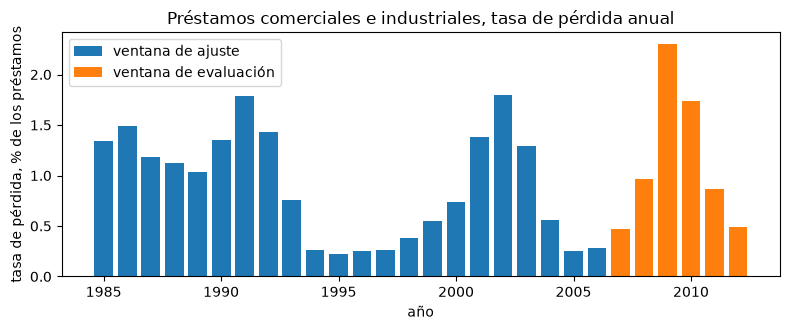

año más alto: 2009 tasa 0.02303


In [3]:
# Dibujar las tasas de pérdida anuales, coloreando la ventana de ajuste y la de evaluación
years = np.array([r["year"] for r in rows])
rate = np.array([r["loss_rate"] for r in rows])
in_fit = np.array([r["window"] == "fit" for r in rows])

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.bar(years[in_fit], 100 * rate[in_fit], color="tab:blue", label="ventana de ajuste")
ax.bar(years[~in_fit], 100 * rate[~in_fit], color="tab:orange", label="ventana de evaluación")
ax.set_xlabel("año")
ax.set_ylabel("tasa de pérdida, % de los préstamos")
ax.set_title("Préstamos comerciales e industriales, tasa de pérdida anual")
ax.legend()
fig.tight_layout()
plt.show()
print("año más alto:", int(years[rate.argmax()]), "tasa", round(float(rate.max()), 5))

## Método

### Paso 1: por qué los préstamos caen juntos en incumplimiento, y la probabilidad de incumplimiento condicional

El modelo de un factor de Vasicek (2002) da a cada préstamo un retorno latente de activos formado por dos partes normales estándar independientes, una compartida por todos los préstamos y otra propia (el fundamento del modelo y su uso en la fórmula IRB de Basilea están en Gordy, 2003, https://doi.org/10.1016/S1042-9573(03)00040-8):

$$A_i = \sqrt{\rho}\, Z + \sqrt{1-\rho}\, \varepsilon_i$$

El préstamo $i$ cae en incumplimiento cuando $A_i$ queda bajo el umbral $\Phi^{-1}(\mathrm{PD})$, donde $\Phi$ es la función de distribución normal estándar y PD la probabilidad de incumplimiento a través del ciclo. $Z$ es el **factor sistemático**, el estado de la economía que comparten todos los préstamos; un $Z$ bajo es un mal año. $\rho$ es la **correlación de activos**. Dado $Z=z$ los préstamos son independientes y cada uno cae en incumplimiento con la probabilidad condicional

$$p(z) = \Phi\!\left(\frac{\Phi^{-1}(\mathrm{PD}) - \sqrt{\rho}\, z}{\sqrt{1-\rho}}\right)$$

La calcula `conditional_pd` del motor. El pipeline ajustó la PD y la correlación a los 22 años de la ventana de ajuste por máxima verosimilitud (el cuaderno siguiente muestra cómo); aquí tomamos los valores ajustados del artefacto. La celda siguiente los imprime y calcula la PD condicional para un año bueno, uno normal y uno malo.

In [4]:
# Leer la PD y la correlación ajustadas y calcular la PD condicional en un año bueno, uno normal y uno malo
from riskvalidation.engines.vasicek import conditional_pd

ml = out["fit"]["maximum_likelihood"]
pd_hat, rho_hat = ml["pd"]["estimate"], ml["rho"]["estimate"]
print("PD ajustada:", round(pd_hat, 6), "| correlación:", round(rho_hat, 6))
print("intervalo al 95% de la correlación:", round(ml["rho"]["ci_low"], 4), "a", round(ml["rho"]["ci_high"], 4))

for label, z in (("año bueno", 1.0), ("año normal", 0.0), ("año malo", -2.0), ("año muy malo", -3.0)):
    print(f"{label:16s} z = {z:5.1f} | PD condicional = {float(conditional_pd(pd_hat, rho_hat, z)):.5f}")

PD ajustada: 0.009105 | correlación: 0.063677
intervalo al 95% de la correlación: 0.0382 a 0.1158
año bueno        z =   1.0 | PD condicional = 0.00346
año normal       z =   0.0 | PD condicional = 0.00734
año malo         z =  -2.0 | PD condicional = 0.02751
año muy malo     z =  -3.0 | PD condicional = 0.04866


La definición se puede comprobar sin la fórmula. En la celda siguiente fijamos un mal año ($z=-2$), sorteamos la parte idiosincrática de 200.000 préstamos, aplicamos la regla de incumplimiento $A_i < \Phi^{-1}(\mathrm{PD})$ y contamos. Es una comprobación de la definición con 200.000 sorteos, no una segunda implementación del motor: la fracción de incumplimientos debe quedar cerca de $p(-2)$.

In [5]:
# Contar los incumplimientos entre 200,000 préstamos simulados en un año con z = -2 y compararlos con la PD condicional
rng = np.random.default_rng(2024)
z_bad = -2.0
n_loans = 200_000
asset = np.sqrt(rho_hat) * z_bad + np.sqrt(1 - rho_hat) * rng.standard_normal(n_loans)
defaulted = asset < stats.norm.ppf(pd_hat)

fraction = defaulted.mean()
sd = np.sqrt(fraction * (1 - fraction) / n_loans)
print("fracción simulada de incumplimientos:", round(float(fraction), 5), "+/-", round(float(sd), 5))
print("PD condicional del motor:", round(float(conditional_pd(pd_hat, rho_hat, z_bad)), 5))
print("diferencia en errores estándar:", round(float((fraction - conditional_pd(pd_hat, rho_hat, z_bad)) / sd), 2))

fracción simulada de incumplimientos: 0.02787 +/- 0.00037
PD condicional del motor: 0.02751
diferencia en errores estándar: 0.97


### Paso 2: la distribución de pérdidas de una cartera muy grande

Cuando la cartera tiene muchísimos préstamos del mismo tipo, las partes idiosincráticas se promedian y la fracción de incumplimientos es exactamente la PD condicional: $L = p(Z)$. Como $p(z)$ baja cuando $z$ sube, la función de distribución y el cuantil de esta **cartera homogénea grande** (LHP) salen en forma cerrada (Vasicek, 2002; Gordy, 2003):

$$P(L \le x) = \Phi\!\left(\frac{\sqrt{1-\rho}\,\Phi^{-1}(x) - \Phi^{-1}(\mathrm{PD})}{\sqrt{\rho}}\right), \qquad \mathrm{VaR}_q = \Phi\!\left(\frac{\Phi^{-1}(\mathrm{PD}) + \sqrt{\rho}\,\Phi^{-1}(q)}{\sqrt{1-\rho}}\right)$$

El motor las tiene como `lhp_cdf`, `lhp_quantile` y `lhp_pdf`. El cuantil al 99,9% es la fracción de incumplimientos que se supera una vez cada mil años; con $q=0{,}999$ es la PD condicional que usa la fórmula de capital IRB (BCBS, 2005). La celda siguiente calcula los cuantiles en los cinco niveles que guarda el artefacto y los pone junto a los del pipeline, con la versión del motor que los calculó.

In [6]:
# Calcular los cuantiles LHP con el motor y compararlos con los versionados
from riskvalidation.engines.vasicek import lhp_cdf, lhp_pdf, lhp_quantile

print("calculado con riskvalidation", doc["provenance"]["riskvalidation_version"])
print(f"{'q':>7s} {'motor':>12s} {'versionado':>12s} {'diferencia':>12s}")
for row in out["fitted_distribution"]["quantiles"]:
    mine = float(lhp_quantile(row["level"], pd_hat, rho_hat))
    print(f"{row['level']:7.3f} {mine:12.6f} {row['value']:12.6f} {mine - row['value']:12.2e}")

# La función de distribución en algunos niveles de pérdida: qué tan probable es un año con tasa de pérdida a lo más x
for x in (0.005, 0.01, 0.02, 0.04):
    print(f"P(L <= {x:.3f}) = {float(lhp_cdf(x, pd_hat, rho_hat)):.4f}")

calculado con riskvalidation 0.7.0
      q        motor   versionado   diferencia
  0.500     0.007338     0.007338    -3.26e-12
  0.900     0.017598     0.017598    -1.92e-11
  0.950     0.022144     0.022144    -1.03e-11
  0.990     0.033355     0.033355     1.21e-11
  0.999     0.051085     0.051085    -5.64e-12
P(L <= 0.005) = 0.3016
P(L <= 0.010) = 0.6689
P(L <= 0.020) = 0.9309
P(L <= 0.040) = 0.9959


La densidad cuenta lo mismo como una imagen. La celda siguiente dibuja la densidad LHP de la fracción de incumplimientos, marca los cuantiles 50%, 99% y 99,9%, y pone debajo los 22 años de la ventana de ajuste como marcas. Un modelo bien ajustado tiene sus años observados repartidos bajo el cuerpo de la densidad, ninguno lejos en la cola derecha.

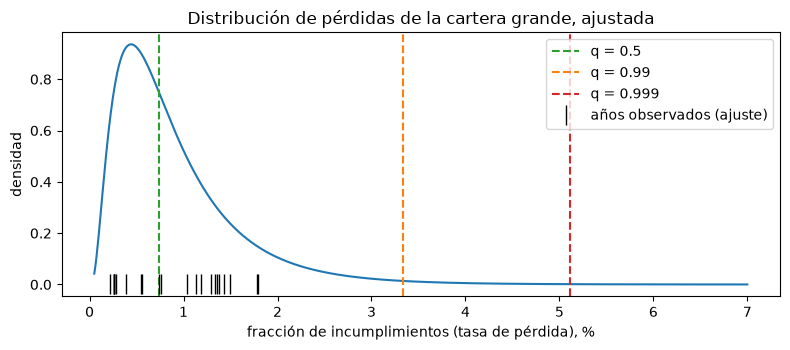

In [7]:
# Dibujar la densidad LHP con sus cuantiles y los años observados de la ventana de ajuste como marcas
grid = np.linspace(0.0005, 0.07, 600)
density = lhp_pdf(grid, pd_hat, rho_hat)

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(100 * grid, density / 100, color="tab:blue")
for q, color in ((0.5, "tab:green"), (0.99, "tab:orange"), (0.999, "tab:red")):
    xq = float(lhp_quantile(q, pd_hat, rho_hat))
    ax.axvline(100 * xq, color=color, linestyle="--", label=f"q = {q}")
ax.plot(100 * rate[in_fit], np.zeros(in_fit.sum()), "|", color="black", markersize=14, label="años observados (ajuste)")
ax.set_xlabel("fracción de incumplimientos (tasa de pérdida), %")
ax.set_ylabel("densidad")
ax.set_title("Distribución de pérdidas de la cartera grande, ajustada")
ax.legend()
fig.tight_layout()
plt.show()

### Paso 3: qué significa un cuantil de pérdida al 99,9% para el capital

Un banco no mantiene capital contra la pérdida promedio, que ya cobra en el precio. Lo mantiene contra la pérdida **inesperada**: la distancia entre un año muy malo y el esperado. Para una cartera de exposición total $E$ y una pérdida dado el incumplimiento $\mathrm{LGD}$, las medidas de la cartera grande son la pérdida esperada $\mathrm{EL}=E\cdot \mathrm{LGD}\cdot \mathrm{PD}$, el valor en riesgo $\mathrm{VaR}_q = E\cdot \mathrm{LGD}\cdot \mathrm{VaR}_q(L)$, el déficit esperado $\mathrm{ES}_q$, la pérdida media en el peor $1-q$ de los años (Acerbi y Tasche, 2002, https://doi.org/10.1016/S0378-4266(02)00283-2), y el capital por pérdida inesperada $\mathrm{EC}_q=\mathrm{VaR}_q-\mathrm{EL}$. El motor las devuelve en `lhp_measures`. Usamos la cartera ilustrativa del caso: 100 millones de USD de exposición y una LGD de 45%; es una cartera construida, nunca la de un banco.

In [8]:
# Calcular EL, VaR, ES y capital de la cartera ilustrativa de 100 millones al 99% y al 99.9%, y compararlos con el primer peldaño versionado
from riskvalidation.portfolio.portfolio import lhp_measures

total_ead = out["portfolio"]["total_ead"]
lgd = out["portfolio"]["lgd_mean"]
measures = lhp_measures(total_ead, lgd, pd_hat, rho_hat, (0.99, 0.999))
c1 = next(r for r in out["rungs"] if r["id"] == "c1-lhp")["measures"]

print("exposición:", f"{total_ead:,.0f}", out["currency"], "| LGD:", lgd)
for m, committed in zip(measures, c1):
    print(f"q = {m.level}: EL = {m.el:,.0f} | VaR = {m.var:,.0f} | ES = {m.es:,.0f} | capital = {m.ec:,.0f}")
    print("        VaR versionado:", f"{committed['var']:,.0f}", "| ES versionado:", f"{committed['es']:,.0f}")
print("capital al 99.9% como parte de la exposición:", round(measures[-1].ec / total_ead, 5))

exposición: 100,000,000 USD | LGD: 0.45
q = 0.99: EL = 409,721 | VaR = 1,500,956 | ES = 1,844,768 | capital = 1,091,236
        VaR versionado: 1,500,956 | ES versionado: 1,844,768
q = 0.999: EL = 409,721 | VaR = 2,298,833 | ES = 2,680,019 | capital = 1,889,113
        VaR versionado: 2,298,834 | ES versionado: 2,680,019
capital al 99.9% como parte de la exposición: 0.01889


### Paso 4: dónde cae cada año observado

La función de distribución convierte la tasa de pérdida de cada año en una posición dentro de la distribución ajustada: $u = P(L \le x)$, un número entre 0 y 1. Un año con $u=0{,}99$ es un año de uno en cien. El mismo año implica también un valor del factor sistemático, la inversa de $p(z)$ (el factor Z de Belkin, Suchower y Forest, 1998; aquí una derivación de la fórmula anterior, no una ecuación citada):

$$\hat z_t = \frac{\Phi^{-1}(\mathrm{PD}) - \sqrt{1-\rho}\,\Phi^{-1}(x_t)}{\sqrt{\rho}}$$

La calcula `implied_factor` del motor. La celda siguiente calcula ambos para los 28 años, los compara con las columnas que versionó el artefacto, y lista los tres peores años.

In [9]:
# Calcular la posición y el factor implícito de cada año, compararlos con las columnas versionadas y listar los peores años
from riskvalidation.engines.vasicek import implied_factor

u = np.array([float(lhp_cdf(x, pd_hat, rho_hat)) for x in rate])
z_hat = np.array([float(implied_factor(x, pd_hat, rho_hat)) for x in rate])
u_file = np.array([r["fitted_cdf"] for r in rows])
z_file = np.array([r["implied_factor"] for r in rows])
print("mayor diferencia con la posición versionada:", f"{np.abs(u - u_file).max():.1e}")
print("mayor diferencia con el factor versionado:", f"{np.abs(z_hat - z_file).max():.1e}")

worst = np.argsort(-u)[:3]
for k in worst:
    print(int(years[k]), rows[k]["window"], "tasa de pérdida", round(float(rate[k]), 5), "| u =", round(float(u[k]), 4), "| z =", round(float(z_hat[k]), 3))
print("años sobre el cuantil 99%:", int((u > 0.99).sum()), "| sobre el cuantil 99.9%:", int((u > 0.999).sum()))

mayor diferencia con la posición versionada: 7.0e-10
mayor diferencia con el factor versionado: 5.3e-09
2009 evaluation tasa de pérdida 0.02303 | u = 0.9562 | z = -1.708
2002 fit tasa de pérdida 0.01798 | u = 0.9057 | z = -1.315
1991 fit tasa de pérdida 0.01785 | u = 0.9038 | z = -1.304
años sobre el cuantil 99%: 0 | sobre el cuantil 99.9%: 0


## Resultados

- **La PD condicional se mueve mucho con la economía.** La PD a través del ciclo del ajuste es 0,9% anual, pero la PD condicional es 0,35% en un año bueno (z = 1), 0,73% en uno normal, 2,75% en uno malo (z = -2) y 4,87% en uno muy malo (z = -3). Los incumplimientos de préstamos distintos no son independientes: los mueve un factor compartido, y eso es lo que hace que la distribución de pérdidas de una cartera sea mucho más ancha que un conteo de préstamos independientes.
- **La definición se cumple.** Contar incumplimientos entre 200.000 préstamos simulados con z = -2 da 2,787% con un error estándar de 0,037%, frente al 2,751% del motor: una diferencia de 0,97 errores estándar, lo que produce el azar por sí solo.
- **La distribución de la cartera grande es asimétrica a la derecha.** La mediana ajustada de la tasa de pérdida es 0,73% y los cuantiles 99% y 99,9% son 3,34% y 5,11%. El motor y el pipeline coinciden hasta cerca de 1e-11, el redondeo del archivo versionado; el pipeline calculó el archivo con el motor 0.7.0 y el motor instalado es el 0.8.1, así que esta coincidencia es una comprobación de reproducibilidad entre dos versiones.
- **Qué significa el cuantil para el capital.** Con 100 millones de USD de exposición y una LGD de 45%, la pérdida esperada es 409.721 USD, el valor en riesgo al 99,9% es 2.298.833 USD y el déficit esperado al 99,9% es 2.680.019 USD. El capital por pérdida inesperada al 99,9% es 1.889.113 USD, 1,9% de la exposición. Las medidas al 99% y al 99,9% difieren porque el capital es una afirmación sobre cuán malo puede ser un año raro, no sobre el promedio.
- **Los años observados caen dentro de la distribución ajustada.** El peor año de toda la serie, 2009, con una tasa de pérdida de 2,30%, está en la posición 0,956 de la distribución ajustada; los dos siguientes, 2002 y 1991, están cerca de 0,90. Ningún año supera el cuantil 99%. Es lo esperable: con 28 años es poco probable que aparezca un año de uno en cien, y un año de uno en mil (el nivel al que se fija el capital) no puede verse, así que estos años no pueden confirmar ni refutar el cuantil 99,9%.

Lo que este cuaderno no muestra: cómo se estimaron la PD y la correlación y cuán inciertas son (cuaderno 02), qué cambia cuando la cartera es finita y concentrada (cuadernos 03 a 05), y cómo se compara el resultado con el capital regulatorio IRB (cuadernos 02 y 07). La cartera es ilustrativa, nunca la de un banco.

## Resumen

- El modelo de un factor explica los incumplimientos conjuntos con un factor sistemático compartido; dado el factor, los préstamos caen en incumplimiento de forma independiente con la PD condicional `conditional_pd`.
- Para una cartera homogénea muy grande la fracción de incumplimientos es la PD condicional, así que su distribución, densidad y cuantiles son fórmulas cerradas (`lhp_cdf`, `lhp_pdf`, `lhp_quantile`), reproducidas aquí hasta cerca de 1e-11 frente al archivo versionado.
- Un cuantil al 99,9% es una tasa de pérdida de una vez cada mil años; el capital es la pérdida inesperada, la distancia entre ese cuantil y la pérdida esperada, y `lhp_measures` devuelve EL, VaR, ES y capital para una cartera.
- Cada año observado tiene una posición en la distribución ajustada y un factor sistemático implícito; 28 años de datos no pueden probar un cuantil al 99,9%.

**Qué probar a continuación.** Cambia `z_bad` en la comprobación por simulación a 0 y a 1 y mira cómo la fracción sigue a la PD condicional. Luego abre el cuaderno 02, donde la PD y la correlación se estiman a partir de las tasas de pérdida y se mide su incertidumbre.

## Referencias

- Gordy, M. B. (2003), A risk-factor model foundation for ratings-based bank capital rules, Journal of Financial Intermediation 12(3):199-232. https://doi.org/10.1016/S1042-9573(03)00040-8
- Board of Governors of the Federal Reserve System, Charge-off and delinquency rates on loans and leases at commercial banks, table chgallsa (public domain; licence class mirror-allowed). https://www.federalreserve.gov/releases/chargeoff/chgallsa.htm
- BCBS, Basel Framework, CRE31: IRB approach, risk weight functions for corporate, bank, sovereign and retail exposures. https://www.bis.org/basel_framework/chapter/CRE/31.htm
- Acerbi, C. y Tasche, D. (2002), On the coherence of expected shortfall, Journal of Banking and Finance 26(7):1487-1503. https://doi.org/10.1016/S0378-4266(02)00283-2
- Vasicek, O. (2002), Loan portfolio value, Risk, December 2002, 160-162 (reprinted in Vasicek, O. (2015), Finance, Economics and Mathematics, Wiley, doi 10.1002/9781119186229.ch19).
- Belkin, B., Suchower, S. y Forest, L. (1998), A one-parameter representation of credit risk and transition matrices, CreditMetrics Monitor, as cited by the engine's `engines.vasicek` module.
- BCBS (2005), An Explanatory Note on the Basel II IRB Risk Weight Functions, https://www.bis.org/publications/explanatory-note-basel-ii-irb-risk-weight-functions.pdf.